# 07 最终策略（final stra）：V2（目标波动 30%）+ 新加坡部分

**组合**：每天的目标仓位 =
- **90% × V2**：02 投票版 → 05 按波动率分配（V1）→ 06 组合波动超过 30% 时缩小风险资产、多出的钱放 BSV
- **10% × 新加坡部分**：ES3 仓位由 03 号 GARCH 波动率目标决定，其余持有 A35

**时间划分**（与全项目一致）：IS 2012-08-01 ~ 2019-12-31；OOS 2020-01-01 ~ 2026-09-30（`OOS_END`）；
实盘 2026-10-01 起由 `08_live_oct_09`（`STRATEGY='final'`）记账，本文件只统计到 9/30。

**成交约定**：T 日收盘得到目标仓位，T+1 开盘调仓（新加坡资产在下一个新加坡开盘成交）；
每天调回目标仓位；成本 = 换手 × 各标的单边成本（`00_engine` 的 `ONE_WAY_BPS`，ES3、A35 各 10 bp）。
美股交易日为主日历；新加坡休市日按上一日价格处理，新加坡单独开市日的涨跌计入下一个美股交易日。

**运行前**依次运行：`1_data/01_data_update` → `03` → `02` → `05` → `06`（生成 `results/signals/` 下的
`ensemble_weights_history.csv`、`sti_weights_history.csv`、`risk_adjusted_weights.csv`、`v2_weights_history.csv`）。

**输出**：`results/tables/final_*.csv`、`results/figures/final_*.png`、`results/signals/final_weights_history.csv`、`final_latest_target.csv`。

In [1]:
from pathlib import Path
import os, json, io, contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


def find_project_root():
    roots = ([Path(os.environ['ETF_PROJECT_ROOT']).expanduser()] if os.environ.get('ETF_PROJECT_ROOT') else [])
    roots += [Path.cwd(), *Path.cwd().parents]
    for root in roots:
        if (root / 'pipeline' / '00_engine.ipynb').is_file():
            return root.resolve()
    raise FileNotFoundError('找不到项目根目录（应包含 pipeline/00_engine.ipynb）。')


ROOT = find_project_root()
PIPELINE_DIR = ROOT / 'pipeline'
TABLE_DIR, FIG_DIR, SIGNAL_DIR = ROOT / 'results' / 'tables', ROOT / 'results' / 'figures', ROOT / 'results' / 'signals'


def load_notebook_definitions(filename):
    """独立命名空间加载函数；不执行被加载 notebook 的入口单元格。"""
    path = next(iter(sorted(PIPELINE_DIR.rglob(filename))), PIPELINE_DIR / filename)   # 在 pipeline 各子文件夹中查找
    nbk = json.loads(path.read_text(encoding='utf-8'))
    ns = {'__name__': 'pipeline_module'}
    for n, item in enumerate(nbk['cells']):
        if item['cell_type'] == 'code' and 'pipeline-entry' not in item.get('metadata', {}).get('tags', []):
            exec(compile(''.join(item['source']), f'{path}:cell{n}', 'exec'), ns)
    return ns


with contextlib.redirect_stdout(io.StringIO()):
    _eng = load_notebook_definitions('00_engine.ipynb')
    _sti = load_notebook_definitions('03_sti_garch.ipynb')     # 只加载函数（load_sti、bootstrap），不运行 03 号
    _slv = load_notebook_definitions('04_sti_sleeve.ipynb')    # 拼仓位的接口，与 08 号实盘账本共用

TICKS, ONE_WAY_BPS = _eng['TICKS'], _eng['ONE_WAY_BPS']
IS_START, IS_END, OOS_START, OOS_END = _eng['IS_START'], _eng['IS_END'], _eng['OOS_START'], _eng['OOS_END']
metrics, fmt = _eng['metrics'], _eng['fmt']
SLEEVE_SHARE = _slv['SLEEVE_SHARE']
PERIODS = [('IS', IS_START, IS_END), ('OOS', OOS_START, OOS_END), ('OOS剔除2020', '2021-01-01', OOS_END)]

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'PingFang SC', 'Noto Sans CJK SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
print(f'已加载 00 / 03 / 04 | 新加坡部分占比 {SLEEVE_SHARE:.0%} | 回测统计截止 {OOS_END} '
      f'| 成本 ES3 {ONE_WAY_BPS.get("ES3")} bp、A35 {ONE_WAY_BPS.get("A35")} bp')

已加载 00 / 10 / 11 | 新加坡部分占比 10% | 回测统计截止 2026-09-30 | 成本 ES3 10.0 bp、A35 10.0 bp


## 1. 价格：美股 + 新加坡（统一成美元、对齐到美股交易日）

In [2]:
def load_prices(csv_path=None):
    """返回 O, C：列 = 9 只美股 ETF + ES3 + A35，行 = 美股交易日，均为复权美元价格。"""
    O_us, H_us, L_us, C_us = _eng['prep'](csv_path)
    idx = C_us.index
    with contextlib.redirect_stdout(io.StringIO()):
        O_e, C_e, O_b, C_b, quality = _sti['load_sti']()          # 新加坡：复权、换算美元、A35 清洗
    if O_b is None:
        raise ValueError('sti_daily.csv 里没有 A35 数据：请先运行 1_data/01_data_update 下载数据。')

    def to_us_calendar(o, c):
        cc = c.reindex(c.index.union(idx)).ffill().reindex(idx)   # 新加坡休市：沿用上一收盘价
        oo = o.reindex(idx)
        return oo.where(oo.notna(), cc), cc                        # 当天新加坡没开市：开盘价 = 收盘价（无涨跌）

    O_es3, C_es3 = to_us_calendar(O_e, C_e)
    O_a35, C_a35 = to_us_calendar(O_b, C_b)
    O, C = O_us.copy(), C_us.copy()
    O['ES3'], C['ES3'], O['A35'], C['A35'] = O_es3, C_es3, O_a35, C_a35
    info = {'美股数据': f'{idx[0].date()} ~ {idx[-1].date()}', '新加坡数据': quality['区间'],
            'A35 清洗天数': quality.get('A35 清洗掉的错误报价天数', '未清洗')}
    return O, C, info

## 2. 仓位：读取各部分的每日目标仓位并合成 final stra

In [3]:
def read_weights(name, cols):
    path = SIGNAL_DIR / name
    if not path.is_file():
        raise FileNotFoundError(f'找不到 {path}，请先运行生成它的 notebook（见开头说明）。')
    w = pd.read_csv(path, index_col=0, parse_dates=True).sort_index()
    return w.reindex(columns=cols).fillna(0.0)


def build_weights(C):
    idx = C.index
    us = {
        'V0': read_weights('ensemble_weights_history.csv', TICKS),
        'V2': read_weights('v2_weights_history.csv', TICKS),
    }
    sg_px = pd.DataFrame(index=idx)                                # 04 号接口只用 index 对齐
    es3_w = _slv['es3_sleeve_signal'](sg_px)
    a35_w = _slv['bond_sleeve_signal'](sg_px)
    assert a35_w.abs().sum() > 0, 'sti_weights_history.csv 里没有 a35_weight，请重新运行 03 号。'

    def combine(us_w):
        us_w = us_w.reindex(idx).dropna(how='all')
        return _slv['combine_with_sleeve'](us_w, es3_w, bond_w=a35_w).fillna(0.0)

    W = {
        'final stra（V2 30% + 新加坡）': combine(us['V2']),
        'V2 30%（纯美股）': us['V2'].reindex(idx).dropna(how='all'),
        'V0 + 新加坡': combine(us['V0']),
        'V0（纯美股）': us['V0'].reindex(idx).dropna(how='all'),
        '新加坡部分（ES3 GARCH + A35）': pd.DataFrame({'ES3': es3_w, 'A35': a35_w}, index=idx).loc[IS_START:],
    }
    for name, w in W.items():
        s = w.sum(axis=1)
        assert ((s > 1 - 1e-6) & (s < 1 + 1e-6)).all(), f'{name} 的仓位之和不等于 1'
    last = {'V2': us['V2'].index.max().date(), 'V0': us['V0'].index.max().date(),
            '新加坡': _slv['_read_weights'](_slv['find_weights_csv']()).index.max().date()}
    return W, last

## 3. 组合回测（与 02 号 `backtest_weighted_portfolio` 同一套规则，扩展到 ES3、A35）

In [4]:
def backtest_weights(O, C, weights, start=IS_START):
    """T 日收盘目标仓位 → T+1 开盘调回目标；成本 = |Δw| × 单边 bps（逐标的）。"""
    names = list(weights.columns)
    idx = C.index[C.index >= pd.Timestamp(start)]
    Oa, Ca = O.loc[idx, names].to_numpy(float), C.loc[idx, names].to_numpy(float)
    Wa = weights.reindex(idx).to_numpy(float)
    rates = np.array([ONE_WAY_BPS[t] for t in names]) / 1e4
    qty = np.zeros(len(names)); nav = 1.0; pending = None
    eq, turn, cost = np.full(len(idx), np.nan), np.zeros(len(idx)), np.zeros(len(idx))
    for k in range(len(idx)):
        if k == 0:
            eq[k] = nav
        else:
            value = float(qty @ Oa[k]) if qty.any() else nav
            if pending is not None:
                old_w = (qty * Oa[k]) / value if qty.any() else np.zeros(len(names))
                delta = pending - old_w
                tc = value * float(np.abs(delta) @ rates)
                qty = (value - tc) * pending / Oa[k]
                turn[k], cost[k] = np.abs(delta).sum(), tc
            nav = float(qty @ Ca[k]); eq[k] = nav
        if not np.isnan(Wa[k]).all():
            pending = np.nan_to_num(Wa[k])
    eq = pd.Series(eq, index=idx)
    diag = pd.DataFrame({'turnover': turn, 'cost': cost}, index=idx)
    return eq, diag


def performance_table(curves, diags):
    rows = []
    for name, eq in curves.items():
        for label, a, b in PERIODS:
            e = eq.loc[a:b]
            if len(e) < 30:
                continue
            t = diags[name]['turnover'].loc[a:b] if name in diags else pd.Series(0.0, index=e.index)
            rows.append({'方案': name, '区间': label, **fmt(metrics(e)),
                         '年化换手': round(float(t.sum() / (len(t) / 252)), 2)})
    return pd.DataFrame(rows)

## 4. 分散化：美股部分与新加坡部分的相关性

In [5]:
def diversification_table(curves):
    us = curves['V2 30%（纯美股）'].pct_change()
    sg = curves['新加坡部分（ES3 GARCH + A35）'].pct_change()
    rows = []
    for label, a, b in PERIODS:
        x, y = us.loc[a:b], sg.loc[a:b]
        ok = x.notna() & y.notna()
        x, y = x[ok], y[ok]
        worst = x <= x.quantile(0.05)
        rows.append({'区间': label, '日收益相关系数': x.corr(y),
                     '美股最差5%交易日: 美股平均收益': x[worst].mean(),
                     '美股最差5%交易日: 新加坡平均收益': y[worst].mean()})
    return pd.DataFrame(rows).set_index('区间')

## 5. 图表与保存

In [6]:
def plot_all(curves, W_final, save):
    figs = {}
    show = ['final stra（V2 30% + 新加坡）', 'V2 30%（纯美股）', 'V0（纯美股）', '新加坡部分（ES3 GARCH + A35）']
    fig, ax = plt.subplots(figsize=(11, 4.8))
    for n in show:
        e = curves[n].loc[:OOS_END]
        ax.plot(e.index, e / e.iloc[0], lw=1.8 if n.startswith('final') else 1.0, label=n)
    ax.axvline(pd.Timestamp(OOS_START), color='gray', ls='--', lw=1)
    ax.set_yscale('log'); ax.set_title(f'净值曲线（对数坐标，截至 {OOS_END}）'); ax.legend(fontsize=8); fig.tight_layout()
    figs['final_equity'] = fig

    fig, ax = plt.subplots(figsize=(11, 3.8))
    for n in show[:3]:
        e = curves[n].loc[:OOS_END]
        ax.plot(e.index, (e / e.cummax() - 1) * 100, lw=1.6 if n.startswith('final') else 1.0, label=n)
    ax.axvline(pd.Timestamp(OOS_START), color='gray', ls='--', lw=1)
    ax.set_ylabel('回撤 (%)'); ax.set_title('回撤对比'); ax.legend(fontsize=8); fig.tight_layout()
    figs['final_drawdown'] = fig

    w = W_final.loc[:OOS_END]
    groups = {'TQQQ': w['TQQQ'], '其他美股杠杆/反向': w[['UVXY', 'TECL', 'SPXL', 'TECS', 'SQQQ']].sum(axis=1),
              'BSV': w['BSV'], 'ES3': w['ES3'], 'A35': w['A35']}
    fig, ax = plt.subplots(figsize=(11, 3.8))
    ax.stackplot(w.index, *groups.values(), labels=list(groups), alpha=0.9)
    ax.set_ylim(0, 1); ax.set_title('final stra 每日仓位'); ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=8)
    fig.tight_layout(); figs['final_weights'] = fig

    if save:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        for n, f in figs.items():
            f.savefig(FIG_DIR / f'{n}.png', dpi=150, bbox_inches='tight')
    plt.show()
    return figs

## 主流程

In [7]:
def main(csv_path=None, n_boot=2000, save=True):
    O, C, info = load_prices(csv_path)
    W, last = build_weights(C)
    print('数据:', info); print('各部分仓位最后日期:', last)

    curves, diags = {}, {}
    for name, w in W.items():
        curves[name], diags[name] = backtest_weights(O, C, w)
    for t in ['SPY', 'ES3']:
        e = C[t].loc[IS_START:]; curves[f'买入持有 {t}'] = e / e.iloc[0]

    print(f'\n① 绩效对比（IS 2012-08 ~ 2019-12 / OOS 2020-01 ~ {OOS_END}，含交易成本）')
    t_perf = performance_table(curves, diags); display(t_perf)

    print('\n② 美股部分（V2）与新加坡部分的分散化')
    t_div = diversification_table(curves); display(t_div.round(4))

    print('\n③ Sharpe 差异的分块 bootstrap 检验（OOS）')
    rows, index = [], []
    main_name = 'final stra（V2 30% + 新加坡）'
    for other in ['V2 30%（纯美股）', 'V0（纯美股）']:
        ra = curves[main_name].loc[OOS_START:OOS_END].pct_change().dropna()
        rb = curves[other].loc[OOS_START:OOS_END].pct_change().dropna()
        ra, rb = ra.align(rb, join='inner')
        rows.append(_sti['block_bootstrap_sharpe_diff'](ra.values, rb.values, n_boot=n_boot))
        index.append(f'final stra vs {other}')
    t_boot = pd.DataFrame(rows, index=index); display(t_boot.round(4))

    W_final = W[main_name]
    last_day = W_final.index[-1]
    latest = W_final.iloc[-1]
    latest = latest[latest.abs() > 1e-9].sort_values(ascending=False).to_frame('目标仓位')
    print(f'\n④ 最新目标仓位（{last_day.date()} 收盘决定，下一交易日开盘执行）'); display(latest.round(4))

    figs = plot_all(curves, W_final, save)
    if save:
        for d in (TABLE_DIR, SIGNAL_DIR): d.mkdir(parents=True, exist_ok=True)
        t_perf.to_csv(TABLE_DIR / 'final_metrics.csv', index=False, encoding='utf-8-sig')
        t_div.to_csv(TABLE_DIR / 'final_diversification.csv', encoding='utf-8-sig')
        t_boot.to_csv(TABLE_DIR / 'final_sharpe_bootstrap.csv', encoding='utf-8-sig')
        pd.DataFrame(curves).to_csv(TABLE_DIR / 'final_equity_history.csv', encoding='utf-8-sig')
        W_final.round(6).to_csv(SIGNAL_DIR / 'final_weights_history.csv', encoding='utf-8-sig')
        latest.to_csv(SIGNAL_DIR / 'final_latest_target.csv', encoding='utf-8-sig')
        print('\n已保存到', ROOT / 'results', '（tables / figures / signals 下的 final_* 文件）')
    return {'curves': curves, 'weights': W, 'metrics': t_perf, 'diversification': t_div,
            'bootstrap': t_boot, 'latest': latest, 'figures': figs}

数据: {'美股数据': '2011-10-03 ~ 2026-10-13', '新加坡数据': '2011-10-03 ~ 2026-10-15', 'A35 清洗天数': 19}
各部分仓位最后日期: {'V2': datetime.date(2026, 10, 13), 'V0': datetime.date(2026, 10, 13), '新加坡': datetime.date(2026, 10, 15)}

① 绩效对比（IS 2012-08 ~ 2019-12 / OOS 2020-01 ~ 2026-09-30，含交易成本）


,方案,区间,CAGR,Vol,Sharpe,Sortino,MDD,Calmar,年化换手
0,final stra（V2 30% + 新加坡）,IS,0.282,0.263,1.079,1.539,-0.397,0.711,52.94
1,final stra（V2 30% + 新加坡）,OOS,0.423,0.272,1.439,2.109,-0.248,1.702,51.63
2,final stra（V2 30% + 新加坡）,OOS剔除2020,0.333,0.264,1.225,1.798,-0.248,1.341,50.51
3,V2 30%（纯美股）,IS,0.309,0.290,1.076,1.539,-0.422,0.734,58.32
4,V2 30%（纯美股）,OOS,0.454,0.301,1.397,2.049,-0.279,1.625,56.76
5,V2 30%（纯美股）,OOS剔除2020,0.350,0.293,1.174,1.721,-0.279,1.252,55.54
6,V0 + 新加坡,IS,0.469,0.396,1.169,1.795,-0.567,0.828,55.17
7,V0 + 新加坡,OOS,1.052,0.534,1.613,2.600,-0.445,2.364,57.70
8,V0 + 新加坡,OOS剔除2020,0.565,0.489,1.162,1.784,-0.445,1.270,55.96
9,V0（纯美股）,IS,0.516,0.439,1.168,1.800,-0.601,0.858,60.45



② 美股部分（V2）与新加坡部分的分散化


,日收益相关系数,美股最差5%交易日: 美股平均收益,美股最差5%交易日: 新加坡平均收益
区间,,,
IS,0.1522,-0.0440,-0.0040
OOS,0.0294,-0.0434,0.0002
OOS剔除2020,0.0158,-0.0413,0.0007



③ Sharpe 差异的分块 bootstrap 检验（OOS）


,Sharpe(主方案),Sharpe(对照),差值,95% CI 下限,95% CI 上限,p值
final stra vs V2 30%（纯美股）,1.4387,1.3968,0.0419,0.0012,0.0846,0.0470
final stra vs V0（纯美股）,1.4387,1.5892,-0.1505,-0.5192,0.2258,0.4185



④ 最新目标仓位（2026-10-13 收盘决定，下一交易日开盘执行）


,目标仓位
TQQQ,0.5041
BSV,0.3959
ES3,0.0592
A35,0.0408


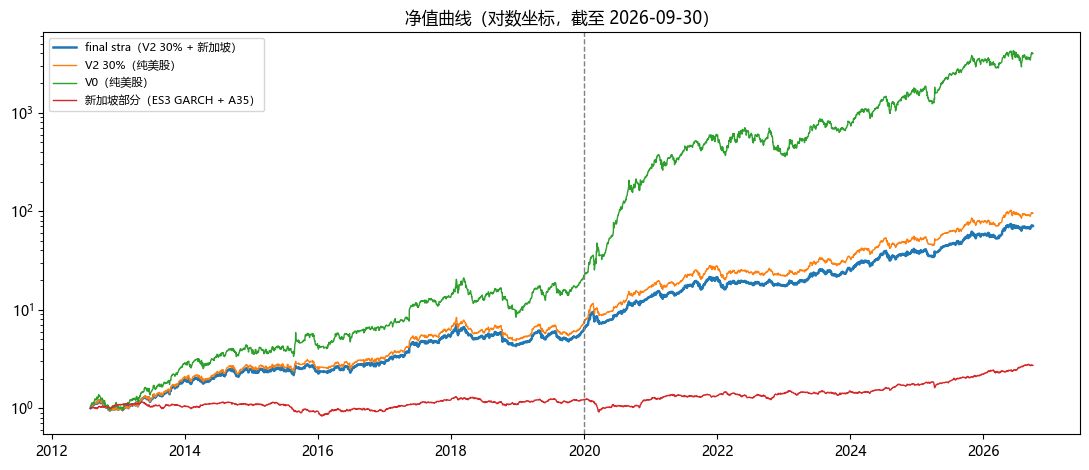

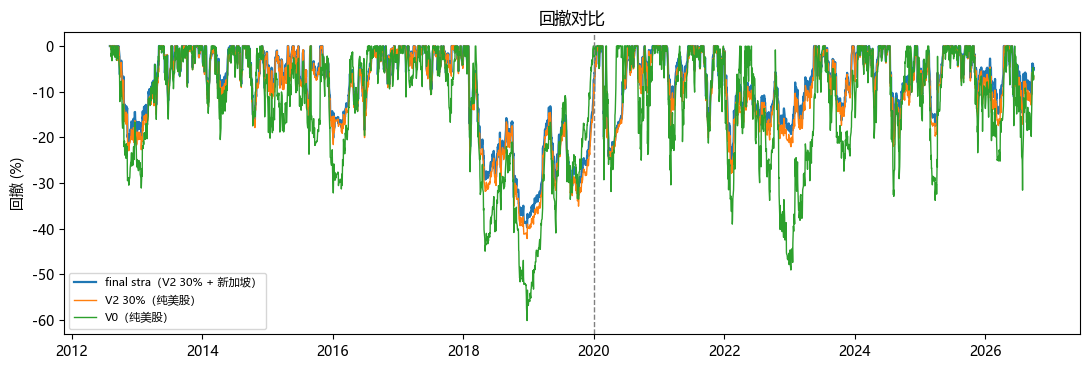

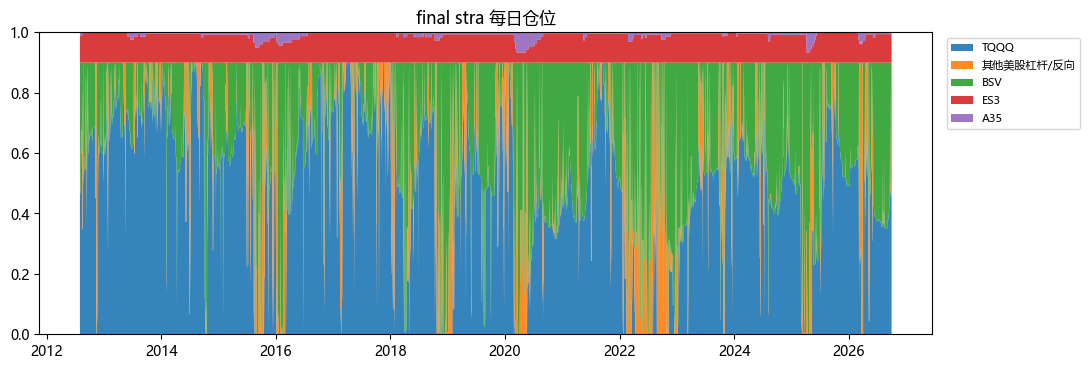


已保存到 E:\subjects\研一\Financial Econometrics\Project\Volumn-Rotation\results （tables / figures / signals 下的 final_* 文件）


In [8]:
# ===== Run All 即可 =====
CSV_PATH = None     # None = data/raw/etf_daily.csv
SAVE = True         # 保存表格、图和仓位到 results/

results_final = main(csv_path=CSV_PATH, save=SAVE)